# Vietnam Real Estate Listings

Exploratory data analysis of Vietnamese property listings from Hugging Face.

* Data source: https://huggingface.co/datasets/tinixai/vietnam-real-estates
* Team:
* Team members:


**Dataset information**

| Column | Meaning |
|---|---|
| `name` | Listing title |
| `description` | Listing description text |
| `property_type_name` | Property category (apartment, house, land, ...) |
| `province_name` | Province / city |
| `district_name` | District |
| `ward_name` | Ward |
| `street_name` | Street |
| `project_name` | Development project name (if any) |
| `price` | Asking price in VND (`null` if not disclosed) |
| `area` | Floor / land area in m² |
| `floor_count` | Number of floors |
| `frontage_width` | Frontage width (m) |
| `house_depth` | Depth (m) |
| `road_width` | Front road width (m) |
| `bedroom_count` | Number of bedrooms |
| `bathroom_count` | Number of bathrooms |
| `house_direction` | Facing direction |
| `balcony_direction` | Balcony facing direction |
| `published_at` | Listing publish timestamp |


**Research objectives**

Purpose: understand how asking prices of Vietnamese property listings vary by location and property type, and how reliable the data is for those comparisons.

1. **Data quality:** How complete, duplicated and valid are the listings, and which rows are kept for price analysis?
2. **Price patterns:** How do asking price and price per m² differ by province, district and property type among listings with disclosed price and area? Do the conclusions hold after removing duplicates?
3. **Associated factors:** Which attributes (area, frontage, floors, bedrooms, bathrooms) are most associated with asking price and price per m²? (Spearman on raw values, Pearson on log10.)

Assumption: every listing is treated as a property for sale, and `price` is the price the seller asks for. Results only cover listings that show a price.


## 0. SET UP


In [ ]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

from eda_utils.config import CATEGORY_COLUMNS, EXPECTED_COLUMNS, RANDOM_STATE
from eda_utils.helpers import (
    clean_data,
    format_price_table,
    pairwise_corr,
    plot_box,
    prepare_priced_data,
    price_summary,
    title_with_n,
)

np.random.seed(RANDOM_STATE)

pd.options.mode.copy_on_write = True
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 12

In [ ]:
parquet_file = "./dataset/vietnam_real_estates.parquet"
if os.path.exists(parquet_file):
    print("Reading dataset...")
    df = pd.read_parquet(parquet_file)
else:
    print("Downloading dataset...")
    ds = load_dataset("tinixai/vietnam-real-estates", cache_dir="./dataset")
    df = ds["train"].to_pandas()

    df.to_parquet(parquet_file, index=False)
print("Rows, columns:", df.shape)

In [ ]:
missing = [c for c in EXPECTED_COLUMNS if c not in df.columns]
extra = [c for c in df.columns if c not in EXPECTED_COLUMNS]
assert not missing, f"Missing columns: {missing}"
assert not extra, f"Unexpected columns: {extra}"
print(f"Schema OK: {len(EXPECTED_COLUMNS)} expected columns present.")

## 1. DATA CLEANING

Conservative cleaning: flag issues, keep all rows in `df_clean`, and build `df_priced` as a separate analytical subset.


### 1.1. Initial data inspection


In [ ]:
print("Shape:", df.shape)
print(df.dtypes)
display(df.head())

In [ ]:
def memory_gb(frame: pd.DataFrame) -> float:
    return frame.memory_usage(deep=True).sum() / (1024 ** 3)

print(f"Memory before category conversion: {memory_gb(df):.3f} GB")

for col in CATEGORY_COLUMNS:
    df[col] = df[col].astype("category")

print(f"Memory after category conversion: {memory_gb(df):.3f} GB")

### 1.2. Missing value analysis

Missing `price` means the asking price was not disclosed. Missing `project_name` often means the listing is not in a named project. Missing directions and dimensions mean the listing did not provide that detail. Rows with missing values are retained.


,n_missing,pct
name,0,0.000000
province_name,0,0.000000
published_at,0,0.000000
description,0,0.000000
property_type_name,0,0.000000
area,4,0.000114
district_name,101933,2.911752
price,218494,6.241359
ward_name,496716,14.188870
street_name,1376860,39.330497


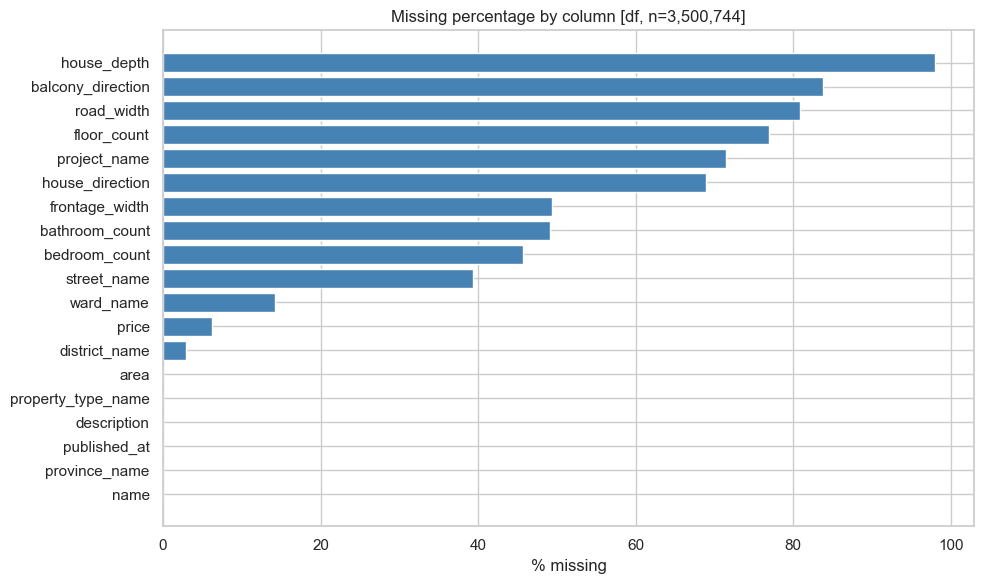

In [ ]:
miss = df.isna().sum().rename("n_missing").to_frame()
miss["pct"] = 100 * miss["n_missing"] / len(df)
miss = miss.sort_values("pct", ascending=False)
display(miss)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(miss.index.astype(str), miss["pct"], color="steelblue")
ax.set_xlabel("% missing")
ax.set_title(title_with_n("Missing percentage by column", "df", len(df)))
plt.tight_layout()
plt.show()

In [ ]:
type_order = df["property_type_name"].value_counts().index
miss_by_type = (
    df.drop(columns="property_type_name").isna()
    .groupby(df["property_type_name"], observed=True).mean()
    .reindex(type_order)
)
fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(miss_by_type, annot=True, fmt=".0%", cmap="Reds", ax=ax)
ax.set_title(title_with_n("Null rate by property type", "df", len(df)))
plt.tight_layout()
plt.show()

Listings without a valid price (price missing or ≤ 0, or area missing or ≤ 0) are excluded from `df_priced`. The tables below show whether these listings are spread evenly across property types, provinces and publication months.

In [ ]:
excluded = ~(df["price"].gt(0) & df["area"].gt(0))
print(f"Share of listings excluded from df_priced: {excluded.mean():.1%}")

month = pd.to_datetime(df["published_at"], errors="coerce").dt.to_period("M")


def excluded_rate(by):
    t = excluded.groupby(by, observed=True).agg(n="size", excluded_rate="mean")
    return t[t["n"] >= 100]


fmt = {"excluded_rate": "{:.1%}"}
print(title_with_n("Excluded share by property type", "df", len(df)))
display(excluded_rate(df["property_type_name"]).sort_values("n", ascending=False).style.format(fmt))
print(title_with_n("Excluded share by province (top 15 by n)", "df", len(df)))
display(excluded_rate(df["province_name"]).sort_values("n", ascending=False).head(15).style.format(fmt))
print(title_with_n("Excluded share by publication month", "df", len(df)))
display(excluded_rate(month).style.format(fmt))

### 1.3. Data type validation and geography / direction checks


In [ ]:
numeric_cols = [
    "price", "area", "floor_count", "frontage_width", "house_depth",
    "road_width", "bedroom_count", "bathroom_count",
]
pub = pd.to_datetime(df["published_at"], errors="coerce")
print("published_at parse nulls:", int(pub.isna().sum()))
print("published_at min/max:", pub.min(), pub.max())
now = pd.Timestamp.now("UTC").tz_localize(None)
pub_naive = pub.dt.tz_localize(None) if pub.dt.tz is not None else pub
print("published_at later than notebook run timestamp:", int((pub_naive > now).sum()))


In [ ]:
print("province nunique:", df["province_name"].nunique(dropna=False))
print("district nunique:", df["district_name"].nunique(dropna=False))
print("Top 20 provinces:\n", df["province_name"].value_counts().head(20))
dist_prov = (
    df.dropna(subset=["district_name"])
    .groupby("district_name", observed=True)["province_name"]
    .nunique()
)
print("district_name values spanning >1 province:", int((dist_prov > 1).sum()))


province nunique: 63
district nunique: 627
Top 20 provinces:
 province_name
Hồ Chí Minh          1357526
Hà Nội               1140542
Đà Nẵng               185973
Bình Dương            150377
Khánh Hòa              98377
Hải Phòng              72788
Hưng Yên               65223
Đồng Nai               59543
Long An                47125
Bà Rịa - Vũng Tàu      45885
Lâm Đồng               26007
Quảng Ninh             20532
Bắc Ninh               20434
Quảng Nam              19997
Hòa Bình               13373
Thanh Hóa              11186
Hà Nam                 11111
Vĩnh Phúc              10803
Huế                    10118
Tây Ninh                9292
Name: count, dtype: int64
district_name values spanning >1 province: 15


In [ ]:
print(title_with_n("house_direction value counts", "df", len(df)))
display(df["house_direction"].value_counts(dropna=False))
print(title_with_n("balcony_direction value counts", "df", len(df)))
display(df["balcony_direction"].value_counts(dropna=False))


house_direction value counts [df, n=3,500,744]


house_direction
NaN                                2414214
Đông Nam                            145317
Nam                                 118194
Đông                                105773
Đông - Nam                          100556
Tây Bắc                              99547
Đông Bắc                             92433
Bắc                                  83539
Tây Nam                              79100
Tây - Bắc                            73043
Tây                                  70330
Đông - Bắc                           64063
Tây - Nam                            54599
Đông, Nam                                5
Đông, Bắc                                5
Tây, Đông Bắc, Tây Nam, Tây Bắc          4
Đông, Đông Nam, Nam, Bắc                 4
Đông Nam, Tây Bắc                        3
Bắc, Tây                                 2
Đông, Đông Nam, Bắc                      1
Đông, Tây Nam                            1
Đông, Tây                                1
Đông Nam, Đông Bắc                    

balcony_direction value counts [df, n=3,500,744]


balcony_direction
NaN                                2933342
Đông Nam                             85314
Đông - Nam                           78628
Nam                                  61650
Đông                                 45675
Đông Bắc                             44389
Tây Bắc                              40810
Bắc                                  40241
Đông - Bắc                           39020
Tây Nam                              35939
Tây - Bắc                            35747
Tây - Nam                            31179
Tây                                  28801
Đông, Đông Nam, Nam, Bắc                 4
Đông - Bắc, Đông - Nam                   2
Tây, Đông Bắc, Tây Nam, Tây Bắc          2
Tây - Bắc, Đông - Nam                    1
Name: count, dtype: int64

### 1.4. Cleaning and analytical dataset creation

Derived columns added to `df_clean` (all 19 originals retained):

| Column | Definition |
|---|---|
| `is_exact_dup` | Exact duplicate over the 19 original columns |
| `is_soft_dup` | Soft-key duplicate |
| `soft_key` | Hash used to identify soft duplicates |
| `flag_nonpositive_price` | `price <= 0` (null → False) |
| `flag_nonpositive_area` | `area <= 0` (null → False) |
| `flag_negative_floor_count` | `floor_count < 0` |
| `flag_negative_bedroom_count` | `bedroom_count < 0` |
| `flag_negative_bathroom_count` | `bathroom_count < 0` |
| `flag_extreme_area` | `area` above 99.9th pct of positive areas |
| `flag_extreme_floor_count` | above 99.9th pct of non-negative values |
| `flag_extreme_bedroom_count` | above 99.9th pct of non-negative values |
| `flag_extreme_bathroom_count` | above 99.9th pct of non-negative values |

`df_priced` keeps listings with `price > 0` and `area > 0` (sale-market assumption), and adds `price_per_m2` and `flag_extreme_price_per_m2` only.


In [ ]:
df_clean = clean_data(df)
df_priced = prepare_priced_data(df_clean)

assert len(df_clean) == len(df) and df_clean.index.equals(df.index)
assert (df_priced["price"] > 0).all() and (df_priced["area"] > 0).all()
assert "price_per_m2" not in df_clean.columns

n0 = len(df)
n_price_ok = int(df_clean["price"].gt(0).sum())
n_priced = len(df_priced)
print(f"df / df_clean: {n0:,} rows")
print(f"after excluding missing/nonpositive price: {n_price_ok:,} "
      f"(excluded {n0 - n_price_ok:,}, {(n0 - n_price_ok) / n0:.2%})")
print(f"after excluding missing/nonpositive area (= df_priced): {n_priced:,} "
      f"(excluded {n_price_ok - n_priced:,}, {(n_price_ok - n_priced) / n0:.2%})")

In [ ]:
print(f"Share of df_priced rows with price < 10,000,000 VND: {(df_priced['price'] < 10_000_000).mean():.2%}")
print("df_priced price percentiles (1, 50, 99):")
print(df_priced["price"].quantile([0.01, 0.50, 0.99]))

#### Duplicate report and extreme tails

Exact and soft duplicates are reported only. Nothing is deleted.

In [ ]:
for name, col in [("Exact", "is_exact_dup"), ("Soft", "is_soft_dup")]:
    print(f"{name} duplicates (keep=first): {df_clean[col].sum():,} ({df_clean[col].mean():.2%})")

cluster_sizes = df_clean["soft_key"].value_counts()
top_clusters = cluster_sizes[cluster_sizes > 1].head(10)
examples = (
    df_clean[df_clean["soft_key"].isin(top_clusters.index)]
    .drop_duplicates("soft_key")
    .assign(cluster_size=lambda d: d["soft_key"].map(top_clusters))
    .sort_values("cluster_size", ascending=False)
)
print(title_with_n("10 largest soft-duplicate clusters (one example row each)", "df_clean", len(df_clean)))
display(examples[["cluster_size", "name", "province_name", "district_name", "price", "area"]])

In [ ]:
cols_show = ["name", "province_name", "price", "area", "price_per_m2"]
for col in ["area", "price_per_m2"]:
    q = df_priced[col].quantile([0.01, 0.99, 0.999])
    print(f"{col} percentiles 1/99/99.9:\n", q)
    lo, hi = q.loc[0.01], q.loc[0.999]
    below = df_priced[df_priced[col] < lo]
    above = df_priced[df_priced[col] > hi]
    print(f"5 random rows below 1st pct ({col}):")
    display(below.sample(n=min(5, len(below)), random_state=RANDOM_STATE)[cols_show])
    print(f"5 random rows above 99.9th pct ({col}):")
    display(above.sample(n=min(5, len(above)), random_state=RANDOM_STATE)[cols_show])

## 2. EXPLORATORY DATA ANALYSIS

All listings are treated as for sale. Price-specific figures use `df_priced` (positive price and area) unless noted. Group statistics require **n ≥ 100**.


### 2.1. General dataset profile


In [ ]:
display(df_clean[numeric_cols].describe())
print(title_with_n("Numeric profile", "df_clean", len(df_clean)))

### 2.2. Price distributions


In [ ]:
fig, axes = plt.subplots(2, 2)
panels = [
    (axes[0][0], "price", False, "Price (VND)", "steelblue"),
    (axes[0][1], "price", True, "Price log10(VND)", "darkorange"),
    (axes[1][0], "area", False, "Area (m2)", "seagreen"),
    (axes[1][1], "area", True, "Area log10(m2)", "darkorange"),
]
for ax, col, log_x, title, color in panels:
    values = np.log10(df_priced[col]) if log_x else df_priced[col]
    ax.hist(values, bins=60, color=color)
    ax.set_title(title_with_n(title, "df_priced", len(df_priced)))
    ax.set_xlabel(f"log10({col})" if log_x else col)

plt.tight_layout()
plt.show()

### 2.3. Property type and Geographical analysis

Medians of `df_priced` (prices are skewed). Price is shown in billion VND and price per m² in million VND. Groups need n ≥ 100.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col, top_n, title in [
    (axes[0], "property_type_name", 8, "Property type share"),
    (axes[1], "province_name", 8, "Province share"),
]:
    share = df_clean[col].value_counts(normalize=True, dropna=False) * 100
    top = share.head(top_n)
    if len(share) > top_n:
        top = pd.concat([top, pd.Series({"Other": share.iloc[top_n:].sum()})])
    top = top.iloc[::-1]

    ax.barh(top.index.astype(str), top.values, color="steelblue")
    for y, v in enumerate(top.values):
        ax.text(v, y, f" {v:.1f}%", va="center", fontsize=9)
    ax.set_xlabel("% of listings")
    ax.set_xlim(0, top.values.max() * 1.15)
    ax.set_title(title_with_n(title, "df_clean", len(df_clean)))

plt.tight_layout()
plt.show()

In [ ]:
type_summary = price_summary(df_priced, "property_type_name")
prov_summary = price_summary(df_priced, "province_name")

print(title_with_n("Median price and price per m² by property type", "df_priced", len(df_priced)))
display(format_price_table(type_summary))
print(title_with_n("Median price and price per m² by province (top 15 by n)", "df_priced", len(df_priced)))
display(format_price_table(prov_summary.head(15)))

In [ ]:
dist_summary = price_summary(df_priced, ["province_name", "district_name"])

print(title_with_n("Median price and price per m² by district (top 15 by n)", "df_priced", len(df_priced)))
display(format_price_table(dist_summary.head(15)))

In [ ]:
top_prov = df_priced["province_name"].value_counts().head(10).index
type_order = df_priced["property_type_name"].value_counts().index
sub = df_priced[df_priced["province_name"].isin(top_prov)]
cell_stats = (
    sub.groupby(["province_name", "property_type_name"], observed=True)["price_per_m2"]
    .agg(n="size", median="median")
    .reset_index()
)
cell_stats = cell_stats[cell_stats["n"] >= 100]
heat = cell_stats.pivot(index="province_name", columns="property_type_name", values="median") / 1e6
heat = heat.reindex(index=top_prov, columns=type_order)
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "million VND / m²"}, ax=ax)
ax.set_title(title_with_n(
    "Median price_per_m2 by province × property type (n≥100 cells)",
    "df_priced",
    len(df_priced),
))
plt.tight_layout()
plt.show()

### 2.4. Area–price relationships


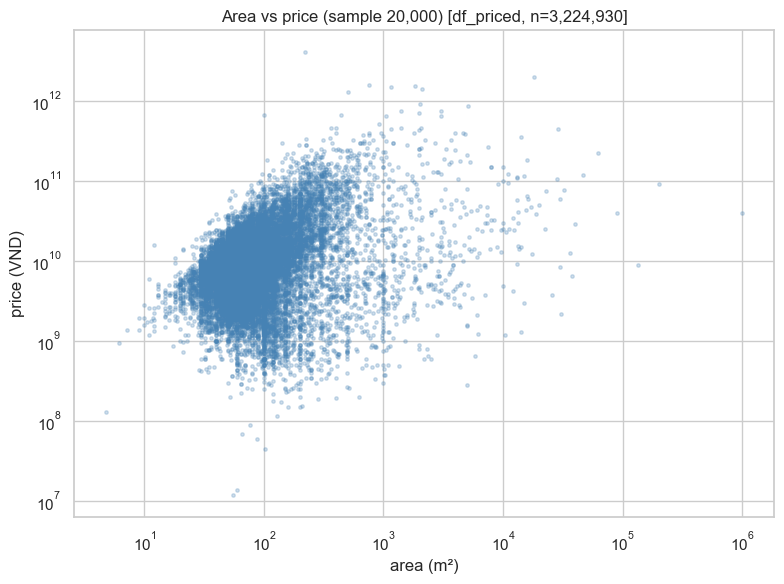

In [ ]:
scatter_n = min(20_000, len(df_priced))
scatter_df = df_priced.sample(n=scatter_n, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(scatter_df["area"], scatter_df["price"], s=6, alpha=0.25, c="steelblue")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("area (m²)")
ax.set_ylabel("price (VND)")
ax.set_title(title_with_n(f"Area vs price (sample {scatter_n:,})", "df_priced", len(df_priced)))
plt.tight_layout()
plt.show()


In [ ]:
plot_box(df_priced, "property_type_name", "price", type_order,
         "price (VND)", "Asking price by property type")

### 2.5. Price per square meter analysis


In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(np.log10(df_priced["price_per_m2"]), bins=60, color="purple")
ax.set_title(title_with_n("price_per_m2 log10 scale", "df_priced", len(df_priced)))
ax.set_xlabel("log10(price_per_m2)")
plt.tight_layout()
plt.show()

In [ ]:
plot_box(df_priced, "province_name", "price_per_m2", top_prov,
         "price_per_m2 (VND/m²)", "price_per_m2 by province (top 10 by n)")

In [ ]:
plot_box(df_priced, "property_type_name", "price_per_m2", type_order,
         "price_per_m2 (VND/m²)", "price_per_m2 by property type")

### 2.6. Correlation analysis

Spearman on raw values, and Pearson on log10-transformed price, area and price_per_m2. Pairwise deletion on `df_priced`; pairs with n < 1,000 are not reported.

In [ ]:
CORR_COLS = [
    "price", "price_per_m2", "area", "floor_count", "frontage_width",
    "house_depth", "road_width", "bedroom_count", "bathroom_count",
]
spearman1, n1 = pairwise_corr(df_priced, CORR_COLS, method="spearman")

print(title_with_n("Pairwise n", "df_priced", len(df_priced)))
display(n1.astype(int))
print("Pairs with n < 1000 are NaN (not reported) in correlation matrices.")

In [ ]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(spearman1.astype(float), annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title(title_with_n("Spearman", "df_priced", len(df_priced)))
plt.tight_layout()
plt.show()

In [ ]:
log_frame = df_priced.copy()
for c in ["price", "area", "price_per_m2"]:
    log_frame[f"log10_{c}"] = np.log10(log_frame[c].where(log_frame[c] > 0))
log_cols = ["log10_price", "log10_area", "log10_price_per_m2"] + [
    c for c in CORR_COLS if c not in {"price", "area", "price_per_m2"}
]
pearson_log, _ = pairwise_corr(log_frame, log_cols, method="pearson")
print(title_with_n("Pearson with log10(price, area, price_per_m2)", "df_priced", len(df_priced)))
display(pearson_log)


### 2.7. Anomaly investigation and duplicate sensitivity


In [ ]:
flag_cols = [c for c in df_clean.columns if c.startswith("flag_")]
print(title_with_n("Extreme / validity flag counts", "df_clean", len(df_clean)))
display(df_clean[flag_cols].sum().rename("count").to_frame())
print("flag_extreme_price_per_m2 on df_priced:", int(df_priced["flag_extreme_price_per_m2"].sum()))


Extreme / validity flag counts [df_clean, n=3,500,744]


,count
flag_nonpositive_price,57320
flag_nonpositive_area,0
flag_negative_floor_count,0
flag_negative_bedroom_count,0
flag_negative_bathroom_count,0
flag_extreme_area,3500
flag_extreme_floor_count,651
flag_extreme_bedroom_count,1799
flag_extreme_bathroom_count,1742


flag_extreme_price_per_m2 on df_priced: 6400


In [ ]:
def summarize_priced(frame):
    return pd.Series({
        "n": len(frame),
        "median_price": frame["price"].median(),
        "median_area": frame["area"].median(),
        "median_price_per_m2": frame["price_per_m2"].median(),
    })


sens = pd.DataFrame({
    "df_priced": summarize_priced(df_priced),
    "no_soft_dup": summarize_priced(df_priced.loc[~df_priced["is_soft_dup"]]),
})
sens["abs_diff"] = sens["no_soft_dup"] - sens["df_priced"]
sens["pct_diff"] = sens["abs_diff"] / sens["df_priced"]
print(title_with_n("Duplicate sensitivity (overall)", "df_priced", len(df_priced)))
display(sens)

### 2.8. Key findings and summary

Wording is associational; prices are asking prices.

In [ ]:
top_prov_row = prov_summary.loc[prov_summary["median_price_per_m2"].idxmax()]
bot_prov_row = prov_summary.loc[prov_summary["median_price_per_m2"].idxmin()]
top_type_row = type_summary.loc[type_summary["median_price_per_m2"].idxmax()]

sp_area = spearman1.loc["area", "price"]
sp_n = int(n1.loc["area", "price"])

soft_share_priced = float(df_priced["is_soft_dup"].mean())
med_price = float(df_priced["price"].median())
med_ppm2 = float(df_priced["price_per_m2"].median())

insights = [
    f"1. Among df_priced (n={n_priced:,}), median asking price is {med_price:,.0f} VND and median asking price_per_m2 is {med_ppm2:,.0f} VND/m².",
    f"2. Among provinces with n≥100, median asking price_per_m2 is highest in {top_prov_row['province_name']} ({top_prov_row['median_price_per_m2']:,.0f} VND/m², n={int(top_prov_row['n']):,}) and lowest in {bot_prov_row['province_name']} ({bot_prov_row['median_price_per_m2']:,.0f} VND/m², n={int(bot_prov_row['n']):,}).",
    f"3. Among property types with n≥100, median asking price_per_m2 is highest for {top_type_row['property_type_name']} ({top_type_row['median_price_per_m2']:,.0f} VND/m², n={int(top_type_row['n']):,}).",
    f"4. Area is associated with asking price (Spearman={sp_area:.3f}, pairwise n={sp_n:,}) on df_priced.",
    f"5. Soft-duplicate rows are {soft_share_priced:.1%} of df_priced (n={n_priced:,}); removing them changes overall medians as shown in the duplicate-sensitivity table.",
]
for line in insights:
    print(line)